In [ ]:
# 匯入套件：Conv2D 卷積層、MaxPooling2D 池化層、Flatten 攤平層、Dense 全連接層
from tensorflow import keras
from keras.models import Sequential
from keras.layers import Dense, Conv2D, MaxPooling2D, Flatten

model = Sequential()
# 第一個卷積層：32 個 3x3 濾波器，輸入為 28x28 單通道（灰階）影像
model.add(Conv2D(filters=32, kernel_size=(3, 3), input_shape=(28, 28, 1), activation='relu'))
# 池化層：每 2x2 取最大值，縮小特徵圖並保留主要特徵
model.add(MaxPooling2D(pool_size=(2, 2)))
# 第二個卷積層：64 個 3x3 濾波器，擷取更高階的特徵
model.add(Conv2D(filters=64, kernel_size=(3, 3), activation='relu'))
model.add(MaxPooling2D(pool_size=(2, 2)))
# 攤平成 1D 向量，接上全連接層
model.add(Flatten())
# 輸出層：10 類（數字 0~9），softmax 輸出機率
model.add(Dense(10, activation='softmax'))
# 印出各層輸出形狀與參數數量
model.summary()
# 標籤會轉成 one-hot，所以損失函數用 categorical_crossentropy
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10)             │        16,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 34,826 (136.04 KB)

 Trainable params: 34,826 (136.04 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# 載入 MNIST 資料集
mnist = keras.datasets.mnist
(train_data, train_label), (test_data, test_label) = mnist.load_data()

# 保留原始整數標籤，稍後畫混淆矩陣（crosstab）要用
test_label_original = test_label

# 影像資料：加上通道維度 (N, 28, 28) -> (N, 28, 28, 1)，並正規化到 0~1
train_data = train_data.reshape(-1, 28, 28, 1).astype('float32') / 255.0
test_data = test_data.reshape(-1, 28, 28, 1).astype('float32') / 255.0

# 標籤轉成 one-hot 編碼，例如 3 -> [0,0,0,1,0,0,0,0,0,0]
train_label = keras.utils.to_categorical(train_label)
test_label = keras.utils.to_categorical(test_label)

In [ ]:
# 訓練：8 個 epoch，每批 128 筆
# validation_split=0.1：拿 10% 訓練資料當驗證集，用來觀察是否過擬合
train_history = model.fit(train_data, train_label, epochs=8, batch_size=128, validation_split=0.1)

Epoch 1/8


  1/422 ━━━━━━━━━━━━━━━━━━━━ 38:04 5s/step - accuracy: 0.1406 - loss: 2.3040

  4/422 ━━━━━━━━━━━━━━━━━━━━ 9s 24ms/step - accuracy: 0.1797 - loss: 2.2658 

  6/422 ━━━━━━━━━━━━━━━━━━━━ 11s 27ms/step - accuracy: 0.1953 - loss: 2.2390

  9/422 ━━━━━━━━━━━━━━━━━━━━ 10s 26ms/step - accuracy: 0.2274 - loss: 2.1917

...

414/422 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.9915 - loss: 0.0265

416/422 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.9915 - loss: 0.0264

419/422 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.9914 - loss: 0.0265

422/422 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.9915 - loss: 0.0264

422/422 ━━━━━━━━━━━━━━━━━━━━ 20s 24ms/step - accuracy: 0.9915 - loss: 0.0264 - val_accuracy: 0.9895 - val_loss: 0.0413


In [ ]:
# 用測試集評估模型，score[1] 為測試準確率
score = model.evaluate(test_data, test_label)
print(score[1])

  1/313 ━━━━━━━━━━━━━━━━━━━━ 6s 22ms/step - accuracy: 1.0000 - loss: 9.9419e-04

 19/313 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9934 - loss: 0.0244     

 38/313 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9877 - loss: 0.0408

 57/313 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9830 - loss: 0.0516

 76/313 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9819 - loss: 0.0538

...

261/313 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9860 - loss: 0.0430

279/313 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9868 - loss: 0.0405

297/313 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9876 - loss: 0.0382

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9871 - loss: 0.0403


0.9871000051498413


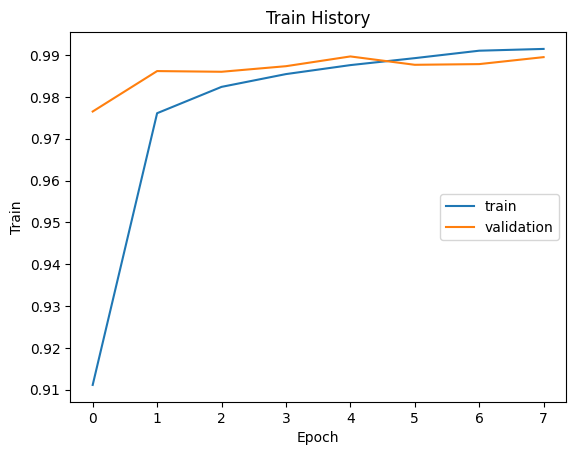

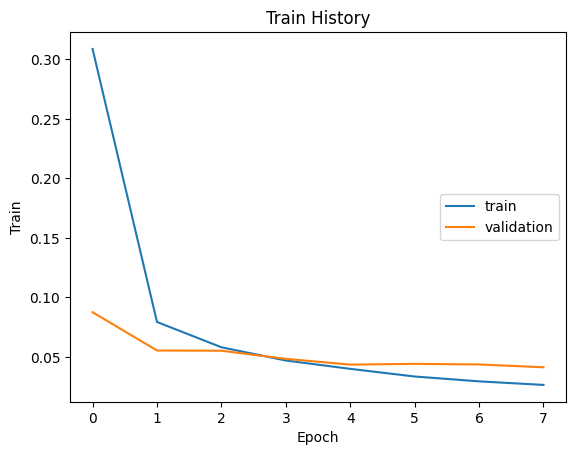

  1/313 ━━━━━━━━━━━━━━━━━━━━ 15s 50ms/step

 21/313 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step  

 41/313 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step

 61/313 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step

 81/313 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step

...

299/313 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


(10000, 10)


predict,0,1,2,3,4,5,6,7,8,9
label,,,,,,,,,,
0,975,0,0,0,0,0,1,3,1,0
1,0,1135,0,0,0,0,0,0,0,0
2,3,10,995,6,1,0,1,14,2,0
3,0,0,1,1001,0,4,0,1,3,0
4,0,0,0,0,980,0,0,0,0,2
5,1,0,0,4,0,883,1,1,2,0
6,4,2,0,0,2,5,944,0,1,0
7,0,4,1,2,0,1,0,1019,0,1
8,4,0,1,7,2,1,0,3,954,2


In [ ]:
# 繪製準確率與損失的訓練歷史圖
import matplotlib.pyplot as plt
import numpy as np

def show_train_history(train_history, train, validation):
    plt.plot(train_history.history[train])        # 訓練集曲線
    plt.plot(train_history.history[validation])   # 驗證集曲線
    plt.title('Train History')
    plt.ylabel('Train')
    plt.xlabel('Epoch')
    plt.legend(['train', 'validation'], loc='center right')
    plt.show()

show_train_history(train_history, 'accuracy', 'val_accuracy')
show_train_history(train_history, 'loss', 'val_loss')

# 混淆矩陣：橫軸為預測、縱軸為真實標籤，可看出哪些數字容易被認錯
import pandas as pd
prediction = model.predict(test_data)                 # 每張圖對 10 類的機率
prediction_label = np.argmax(prediction, axis=1)      # 取機率最大者為預測類別
print(test_label.shape)
pd.crosstab(test_label_original, prediction_label, rownames=['label'], colnames=['predict'])